# Sending text through phase: a full link with phase recovery

This notebook puts phase recovery to work end to end. A text message is turned into bits, the bits into optical **phases**, the light goes through fiber dispersion, and the receiver sees **only intensity**. Phase recovery gets the phases back, and the bits become text again.

```
text -> bytes -> bits + CRC-4 -> QPSK symbols -> smooth phase -> [ dispersions D1..D5 ] -> photodetectors |E|^2
                                                                                                   |
text <- bytes <- bits, CRC check <- symbol decisions <- pilot alignment <- phase recovery (multi-plane GS)
```

Everything here is **simulated** (normalized dispersion units, Gaussian detector noise, fixed random seeds). Change `MESSAGE` below to send anything.

In [1]:
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'dgs'))
import gs_core as gs                         # disperse / undisperse: the dispersion model used everywhere in this repo

MESSAGE = 'IEEE CpE: phase recovered!'
SPS = 32                                     # samples per symbol
DS = (-2500.0, -5000.0, -10000.0, -20000.0, -40000.0)   # five dispersion settings (normalized units)

## 1. Transmitter: text to phase

- **Framing.** Each character (1 byte) gets its own frame: 2 known **pilot** symbols, 4 data symbols (8 bits), and 2 symbols of **CRC-4** checksum (4 bits). That's 8 QPSK symbols per frame.
- **QPSK with a Gray code.** Each symbol is one of four phases, π/4 + kπ/2. The bit labels follow a Gray code (00, 01, 11, 10 going around the circle), so a small phase error flips only one bit.
- **Smooth phase.** The phase glides from one symbol to the next along a cosine curve instead of jumping. The light keeps a **constant amplitude**, and its spectrum stays narrow enough for phase recovery to work (section 4 shows why that matters).

In [2]:
GRAY = {0b00: 0, 0b01: 1, 0b11: 2, 0b10: 3}        # 2 bits -> quadrant (neighbours differ in one bit)
INV = {v: k for k, v in GRAY.items()}
PILOT = [0, 1]

def crc4(byte):
    # CRC-4 with polynomial x^4 + x + 1: catches every 1-bit and 2-bit error in a frame
    reg = 0
    for i in range(7, -1, -1):
        top = (reg >> 3) & 1
        reg = ((reg << 1) & 0xF) ^ (0b0011 if top ^ ((byte >> i) & 1) else 0)
    return reg

def frame_symbols(byte):
    bits = f'{byte:08b}{crc4(byte):04b}'
    return PILOT + [GRAY[int(bits[i:i+2], 2)] for i in range(0, 12, 2)]

def smooth_phase(sym):
    ph = np.unwrap(np.pi/4 + np.array(sym)*np.pi/2)          # take the short way between neighbouring phases
    t = np.arange(len(sym)*SPS)/SPS; k = np.floor(t).astype(int); fr = t - k
    nxt = np.minimum(k + 1, len(sym) - 1)
    return ph[k] + (ph[nxt] - ph[k])*0.5*(1 - np.cos(np.pi*fr))

example = MESSAGE.encode('utf-8')[0]
print(f"first character {chr(example)!r} = byte {example} = bits {example:08b}, CRC-4 {crc4(example):04b}")
print('frame symbols (quadrants):', frame_symbols(example))

first character 'I' = byte 73 = bits 01001001, CRC-4 1111
frame symbols (quadrants): [0, 1, 1, 0, 3, 1, 2, 2]


## 2. Channel and detectors

The light passes through five dispersion settings, and five photodetectors record only the intensity |E|² after each one, with noise added. The phase is not measured anywhere.

In [3]:
def channel(byte, snr_db, rng):
    E = np.exp(1j*smooth_phase(frame_symbols(byte)))
    s = 10**(-snr_db/20)
    Is = [np.abs(gs.disperse(E, D))**2 for D in DS]
    return E, [np.maximum(I + s*np.mean(I)*rng.standard_normal(I.size), 0) for I in Is]

## 3. Receiver: phase recovery, then bits

1. **Multi-plane Gerchberg-Saxton.** Cycle through the five measurements. At each one, keep the measured magnitude and the current phase, then undo that dispersion. After every step, impose the constant amplitude.
2. **Pilot alignment.** Intensity can't reveal a constant phase offset or a sign flip (proved in Lean in `lean/PhaseRetrieval.lean`). The two known pilot symbols fix both.
3. **Decisions and CRC.** Round each symbol to the nearest QPSK point, map Gray labels back to bits, and check the CRC-4. If the pilots or the CRC are wrong, run the recovery again from a new random start, up to 10 times. If every try fails, the character is **flagged** as unreliable.

In [4]:
def recover(amps, E0, n_iter=100):
    E = np.exp(1j*np.angle(E0))
    for _ in range(n_iter):
        for a, D in zip(amps, DS):
            E = np.exp(1j*np.angle(gs.undisperse(a*np.exp(1j*np.angle(gs.disperse(E, D))), D)))
    return np.angle(E)

def decisions(phr):
    z = np.exp(1j*phr[np.arange(8)*SPS])                              # one sample per symbol
    ref = np.exp(1j*(np.pi/4 + np.array(PILOT)*np.pi/2))
    for zz in (z, np.conj(z)):                                       # both signs (conjugation ambiguity)
        off = np.angle(np.sum(ref*np.conj(zz[:2])))                  # constant offset from the pilots
        yield (np.round((np.angle(zz*np.exp(1j*off)) - np.pi/4)/(np.pi/2)) % 4).astype(int)

def receive(Is, rng, max_tries=10):
    amps = [np.sqrt(I) for I in Is]
    byte = 0
    for attempt in range(max_tries):
        E0 = gs.undisperse(amps[0].astype(complex), DS[0]) if attempt == 0 else np.exp(1j*rng.uniform(-np.pi, np.pi, amps[0].size))
        for dec in decisions(recover(amps, E0)):
            if list(dec[:2]) != PILOT: continue
            bits = ''.join(f'{INV[q]:02b}' for q in dec[2:])
            byte, c = int(bits[:8], 2), int(bits[8:], 2)
            if crc4(byte) == c:
                return byte, attempt + 1, True
    return byte, max_tries, False

def send(message, snr_db, seed=0):
    rng = np.random.default_rng(seed)
    out, tries, flags = bytearray(), [], 0
    for byte in message.encode('utf-8'):
        _, Is = channel(byte, snr_db, rng)
        b, n, ok = receive(Is, rng)
        out.append(b); tries.append(n); flags += not ok
    return out.decode('utf-8', errors='replace'), tries, flags

t0 = time.time()
received, tries, flags = send(MESSAGE, snr_db=25, seed=1)
print('sent:     ', repr(MESSAGE))
print('received: ', repr(received))
print(f'identical: {received == MESSAGE} | frames needing a retry: {sum(t > 1 for t in tries)} | flagged: {flags} | {time.time() - t0:.1f} s')

sent:      'IEEE CpE: phase recovered!'
received:  'IEEE CpE: phase recovered!'
identical: True | frames needing a retry: 0 | flagged: 0 | 0.7 s


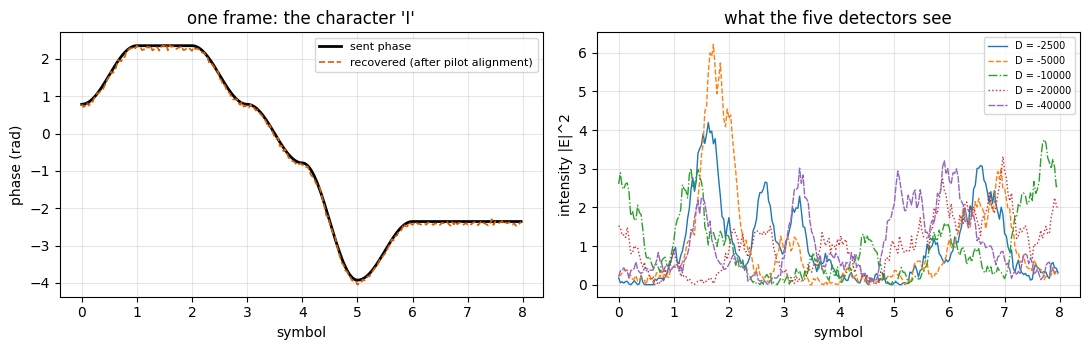

Figure: left, the transmitted phase of one frame (solid black) and the recovered phase (dashed orange), which lie on top
of each other; right, the five intensity traces the detectors record (one line style each); none of them shows the phase directly.


In [5]:
rng = np.random.default_rng(5)
E_tx, Is = channel(MESSAGE.encode('utf-8')[0], 25, rng)
phr = recover([np.sqrt(I) for I in Is], gs.undisperse(np.sqrt(Is[0]).astype(complex), DS[0]))
dec = next(iter(decisions(phr)))
z = np.exp(1j*phr); ref = np.exp(1j*(np.pi/4 + np.array(PILOT)*np.pi/2))
off = np.angle(np.sum(ref*np.conj(z[np.arange(2)*SPS])))
phi_tx = np.unwrap(np.angle(E_tx))                                    # unwrapped: no +pi/-pi jumps in the plot
phi_rx = phi_tx + np.angle(np.exp(1j*(np.angle(z*np.exp(1j*off)) - phi_tx)))   # same angles, drawn next to the sent phase
tt = np.arange(len(phi_tx))/SPS
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(tt, phi_tx, color='#000000', lw=2, ls='-', label='sent phase')
a1.plot(tt, phi_rx, color='#D55E00', lw=1.2, ls='--', label='recovered (after pilot alignment)')
a1.set_xlabel('symbol'); a1.set_ylabel('phase (rad)'); a1.set_title(f'one frame: the character {MESSAGE[0]!r}'); a1.legend(fontsize=8); a1.grid(alpha=0.3)
for I, D, st in zip(Is, DS, ['-', '--', '-.', ':', (0, (5, 1))]):
    a2.plot(tt, I, ls=st, lw=1, label=f'D = {D:g}')
a2.set_xlabel('symbol'); a2.set_ylabel('intensity |E|^2'); a2.set_title('what the five detectors see'); a2.legend(fontsize=7); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Figure: left, the transmitted phase of one frame (solid black) and the recovered phase (dashed orange), which lie on top')
print('of each other; right, the five intensity traces the detectors record (one line style each); none of them shows the phase directly.')

## 4. How noisy can the link be?

Each SNR below sends the whole message. "Flagged" characters are ones the receiver knew it got wrong because the CRC failed on every try. CRC-4 can let a bad frame through about 1 time in 16, so a wrong character can occasionally go unflagged.

In [6]:
print(f'{"SNR (dB)":>9} | {"wrong chars":>11} | {"flagged":>7} | {"retries":>7} | received')
for snr in (10, 15, 20, 30):
    rx, tr, fl = send(MESSAGE, snr, seed=1)
    wrong = sum(a != b for a, b in zip(rx, MESSAGE)) + abs(len(rx) - len(MESSAGE))
    print(f'{snr:>9} | {wrong:>8}/{len(MESSAGE)} | {fl:>7} | {sum(t > 1 for t in tr):>7} | {rx!r}')

 SNR (dB) | wrong chars | flagged | retries | received


       10 |        1/26 |       1 |       1 | 'IEEE CpE: phase recowered!'


       15 |        0/26 |       0 |       0 | 'IEEE CpE: phase recovered!'


       20 |        0/26 |       0 |       0 | 'IEEE CpE: phase recovered!'


       30 |        0/26 |       0 |       0 | 'IEEE CpE: phase recovered!'


## 5. Why five dispersions?

The rest of this repository recovers a smooth phase from **two** dispersions. Data symbols are harder, because their phase changes in steps. The cell below counts, with no noise at all, how many random 8-symbol frames each setup recovers (within 0.2 rad). With too few measurements, several different phases fit the intensities equally well, so the algorithm can settle on a wrong one. Each extra measurement rules more of them out.

In [7]:
def recovered_fraction(Ds, trials=40, seed=3):
    rng = np.random.default_rng(seed); ok = 0
    for _ in range(trials):
        phi = smooth_phase(rng.integers(0, 4, 8)); E = np.exp(1j*phi)
        amps = [np.abs(gs.disperse(E, D)) for D in Ds]
        Er = np.exp(1j*np.angle(gs.undisperse(amps[0].astype(complex), Ds[0])))
        for _ in range(100):
            for a, D in zip(amps, Ds):
                Er = np.exp(1j*np.angle(gs.undisperse(a*np.exp(1j*np.angle(gs.disperse(Er, D))), D)))
        d = phi - np.angle(Er)
        rms = min(np.sqrt(np.mean(np.angle(np.exp(1j*(dd - np.angle(np.sum(np.exp(1j*dd))))))**2)) for dd in (d, phi + np.angle(Er)))
        ok += rms < 0.2
    return ok, trials
for Ds in [(-20000, -23000), (-5000, -10000, -20000), (-2500, -5000, -10000, -20000), DS]:
    ok, n = recovered_fraction(Ds)
    print(f'{len(Ds)} dispersions: {ok}/{n} frames recovered')

2 dispersions: 8/40 frames recovered


3 dispersions: 27/40 frames recovered


4 dispersions: 37/40 frames recovered


5 dispersions: 40/40 frames recovered


## What this shows, and what it doesn't

- **The link works in simulation:** text sent as optical phase is recovered from intensity-only detectors, error-free at 15 dB SNR and above, with errors detected by the CRC near 10 dB.
- **Two measurements are not enough for data symbols.** Two dispersions recover smooth phases well (as elsewhere in this repo) but fail on most QPSK frames. Five recovered every frame tested.
- **Pilots are required,** because the constant offset and the sign of the phase are invisible to intensity.
- **Limits:** all simulated; normalized dispersion units; Gaussian noise; one character per 256-sample frame is a low data rate; five detectors is a lot of hardware. A real system would trade those against each other.